# Between-Model Replay Agreement

Purpose: measure how replay models vary in their replay scores for the same episode and condition.

Inputs:
- Combined replay CSV data from `load_replay_data()`.

Unit of analysis:
- An episode is `(game_id, player_id, turn)`.
- Model-level summaries average the three repetitions per `(episode, replay_model, condition)`.
- Agreement metrics are computed across available replay models within each `(episode, condition)`.

Definitions:
- Cross-model SD is the standard deviation of model-level replay scores.
- Range is max minus min across model-level replay scores.
- Direction agreement is the majority-sign share for replay deltas.


In [ ]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, spearmanr
from IPython.display import display, Markdown

from shared.plot_utilities import (
    setup_notebook_display, get_model_palette, plot_violin,
    pvalue_to_stars, sort_player_types,
)
from shared.regression_utilities import fit_regression
from nuke.utils.load_replay_data import (
    add_canonical_replay_model,
    add_condition_factor_columns,
    load_replay_data,
)

setup_notebook_display()
df = load_replay_data()
df = add_canonical_replay_model(df)
df = add_condition_factor_columns(df)

# Conditions with 2+ models (can compute between-model agreement)
models_per_condition = df.groupby('condition', observed=True)['replay_model_canonical'].nunique()
MULTI_MODEL_CONDITIONS = list(models_per_condition[models_per_condition >= 2].index)
print(f'\nConditions with 2+ models: {MULTI_MODEL_CONDITIONS}')
print(f'Models per condition:\n{models_per_condition.to_string()}')


## 1. Episode-Level Aggregation

Average three repetitions per `(episode, model, condition)` before calculating between-model agreement metrics.

In [ ]:
EPISODE_COLS = ['game_id', 'player_id', 'turn']
METRICS = ['replay_use_nuke', 'replay_nuke']
DELTA_METRICS = ['replay_use_nuke_delta', 'replay_nuke_delta']

# Average over 3 repetitions per (episode, model, condition)
model_means = (
    df.groupby(['condition', *EPISODE_COLS, 'replay_model_canonical'], observed=True)
    [METRICS + DELTA_METRICS]
    .mean()
    .reset_index()
)

# Record how many models per (episode, condition)
n_models = (
    model_means.groupby(['condition', *EPISODE_COLS], observed=True)['replay_model_canonical']
    .nunique()
    .rename('n_models')
    .reset_index()
)

print(f'Model means: {len(model_means):,} rows')
print(f'\nModels per (episode, condition):')
display(n_models.groupby('condition', observed=True)['n_models'].value_counts().unstack(fill_value=0))

Model means: 10,660 rows

Models per (episode, condition):


n_models,10,11
condition,,
original,0,130
no-rationale,130,0
high-stakes,130,0
high-stakes-no-rationale,130,0
ethical,0,130
ethical-high-stakes,130,0
ethical-no-rationale,130,0
high-stakes-no-rationale-ethical,130,0


## 2. Agreement Metric Construction

For each `(episode, condition)`, compute cross-model standard deviation, range, direction agreement, and mean replay score across available models.

In [ ]:
def direction_agreement(deltas):
    """Fraction of values agreeing on the majority sign (+, -, or 0)."""
    signs = np.sign(deltas.dropna())
    if len(signs) == 0:
        return np.nan
    counts = signs.value_counts()
    return counts.max() / len(signs)

# Per-episode agreement metrics
grp = model_means.groupby(['condition', *EPISODE_COLS], observed=True)

episode_agreement = grp.agg(
    use_nuke_std=('replay_use_nuke', 'std'),
    nuke_std=('replay_nuke', 'std'),
    use_nuke_range=('replay_use_nuke', lambda x: x.max() - x.min()),
    nuke_range=('replay_nuke', lambda x: x.max() - x.min()),
    use_nuke_direction_agree=('replay_use_nuke_delta', direction_agreement),
    nuke_direction_agree=('replay_nuke_delta', direction_agreement),
    use_nuke_mean=('replay_use_nuke', 'mean'),
    nuke_mean=('replay_nuke', 'mean'),
).reset_index()

# Merge n_models
episode_agreement = episode_agreement.merge(n_models, on=['condition', *EPISODE_COLS])

# Merge original episode state (one value per episode, take first)
episode_state = (
    df.groupby(EPISODE_COLS, observed=True)
    [['prev_use_nuke', 'after_use_nuke', 'prev_nuke', 'after_nuke',
      'original_use_nuke_delta', 'original_nuke_delta', 'player_type', 'model']]
    .first()
    .reset_index()
)
episode_agreement = episode_agreement.merge(episode_state, on=EPISODE_COLS, how='left')

# Merge condition indicators
cond_indicators = df[['condition', 'no_rationale', 'high_stakes', 'ethical']].drop_duplicates()
episode_agreement = episode_agreement.merge(cond_indicators, on='condition', how='left')

print(f'Episode agreement table: {len(episode_agreement)} rows '
      f'({episode_agreement["condition"].nunique()} conditions)')
display(episode_agreement.head())

Episode agreement table: 1040 rows (8 conditions)


,condition,game_id,player_id,turn,use_nuke_std,nuke_std,use_nuke_range,nuke_range,use_nuke_direction_agree,nuke_direction_agree,use_nuke_mean,nuke_mean,n_models,prev_use_nuke,after_use_nuke,prev_nuke,after_nuke,original_use_nuke_delta,original_nuke_delta,player_type,model,no_rationale,high_stakes,ethical
0,original,0726ff69-1696-4928-996d-9d3979472b05,4,344,5.680909,6.030227,20.000000,21.666667,0.454545,0.454545,88.787879,81.515152,11,90.0,100.0,80.0,100.0,10.0,20.0,GPT-OSS-120B-Simple,openai-compatible/DeepSeek-V3.2,0,0,0
1,original,085cfce3-75ee-4459-b7b0-c49c9a27f651,4,408,2.591751,0.000000,8.333333,0.000000,0.545455,1.000000,82.121212,100.000000,11,80.0,100.0,100.0,100.0,20.0,0.0,GLM-4.7-Simple,openai-compatible/DeepSeek-V3.2,0,0,0
2,original,08b14f7d-5a12-42fc-baa4-7793c0418bdf,6,445,5.379535,1.005038,20.000000,3.333333,0.545455,0.909091,88.787879,99.696970,11,90.0,100.0,100.0,100.0,10.0,0.0,Deepseek-3.2-Simple,openai-compatible/DeepSeek-V3.2,0,0,0
3,original,08f6be09-605d-49fd-96aa-ddf7d0b0bf97,3,421,9.555790,5.025189,26.666667,16.666667,0.818182,0.909091,4.242424,1.515152,11,0.0,100.0,0.0,0.0,100.0,0.0,Kimi-K2.5-Briefed,openai-compatible/DeepSeek-V3.2,0,0,0
4,original,0fb9fca8-e594-458f-8c0e-d11e0d25513e,2,372,1.866775,1.005038,6.666667,3.333333,0.727273,0.909091,94.393939,99.696970,11,95.0,100.0,100.0,100.0,5.0,0.0,Kimi-K2.5-Simple,openai-compatible/DeepSeek-V3.2,0,0,0


## 3. Agreement Summary Tables

Summarize agreement metrics by condition with the number of available replay models shown alongside each table.

In [ ]:
# Filter to multi-model conditions for agreement summaries
ea_multi = episode_agreement[episode_agreement['condition'].isin(MULTI_MODEL_CONDITIONS)].copy()

# Show a cleaner version: mean, median, Q25, Q75 per condition
for metric in ['use_nuke_std', 'nuke_std', 'use_nuke_direction_agree', 'nuke_direction_agree']:
    tbl = ea_multi.groupby('condition', observed=True)[metric].agg(['mean', 'median', 'std']).round(3)
    tbl.index = tbl.index.astype(str)
    # Add n_models info
    tbl['n_models'] = ea_multi.groupby('condition', observed=True)['n_models'].first().values
    display(Markdown(f'### {metric}'))
    display(tbl)

### use_nuke_std

,mean,median,std,n_models
condition,,,,
original,8.107,5.387,7.954,11
no-rationale,12.532,11.448,6.817,10
high-stakes,7.671,5.671,7.325,10
high-stakes-no-rationale,12.766,11.593,7.131,10
ethical,16.139,15.480,8.700,11
ethical-high-stakes,16.137,14.971,9.402,10
ethical-no-rationale,24.135,26.792,9.660,10
high-stakes-no-rationale-ethical,24.425,25.593,9.262,10


### nuke_std

,mean,median,std,n_models
condition,,,,
original,6.643,3.879,7.761,11
no-rationale,12.844,11.527,7.581,10
high-stakes,5.847,3.298,6.989,10
high-stakes-no-rationale,12.243,11.125,7.743,10
ethical,12.908,10.704,10.072,11
ethical-high-stakes,13.138,11.990,10.024,10
ethical-no-rationale,25.126,25.767,8.519,10
high-stakes-no-rationale-ethical,25.504,26.443,8.318,10


### use_nuke_direction_agree

,mean,median,std,n_models
condition,,,,
original,0.655,0.636,0.161,11
no-rationale,0.566,0.500,0.132,10
high-stakes,0.652,0.600,0.153,10
high-stakes-no-rationale,0.591,0.600,0.140,10
ethical,0.576,0.545,0.158,11
ethical-high-stakes,0.590,0.500,0.152,10
ethical-no-rationale,0.679,0.700,0.133,10
high-stakes-no-rationale-ethical,0.701,0.700,0.122,10


### nuke_direction_agree

,mean,median,std,n_models
condition,,,,
original,0.776,0.818,0.177,11
no-rationale,0.590,0.600,0.119,10
high-stakes,0.778,0.800,0.193,10
high-stakes-no-rationale,0.619,0.600,0.138,10
ethical,0.689,0.636,0.189,11
ethical-high-stakes,0.702,0.700,0.178,10
ethical-no-rationale,0.624,0.600,0.118,10
high-stakes-no-rationale-ethical,0.645,0.600,0.114,10


## 4. Agreement Metric Distributions

Plot the distribution of cross-model standard deviations by condition for `replay_use_nuke` and `replay_nuke`.

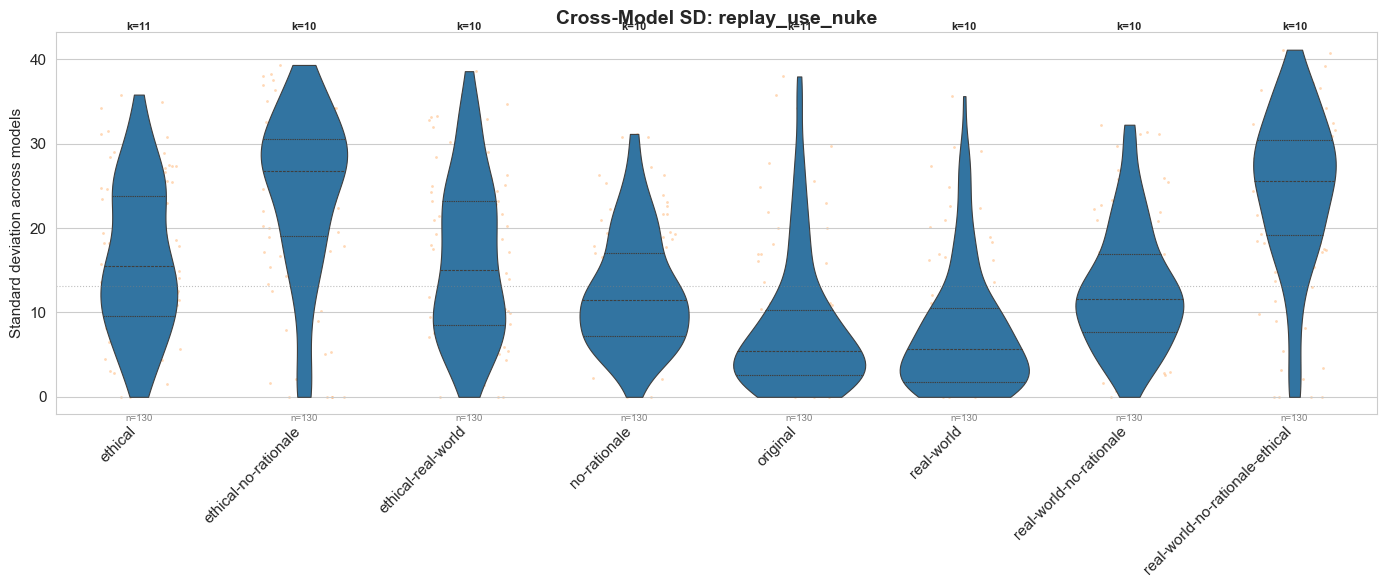

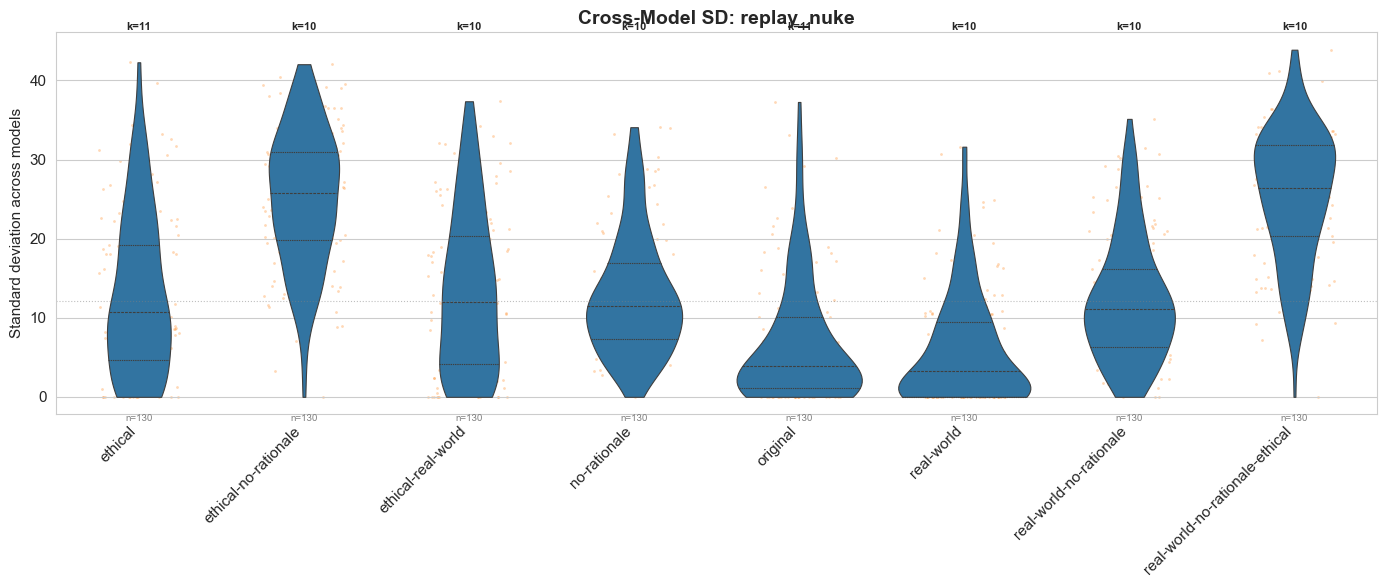

In [ ]:
# Violin plots: cross-model SD by condition
for metric, label in [
    ('use_nuke_std', 'Cross-Model SD: replay_use_nuke'),
    ('nuke_std', 'Cross-Model SD: replay_nuke'),
]:
    annotations = ea_multi.groupby('condition', observed=True)['n_models'].first().to_dict()
    plot_violin(
        ea_multi, y=metric, x='condition',
        title=label,
        ylabel='Standard deviation across models',
        hline=ea_multi[metric].median(),
        annotations=annotations,
        annotation_fmt='k={:.0f}',
        annotation_pos='above',
        strip=True,
    )

## 5. Agreement Regression Specifications

Fit OLS specifications for cross-model standard deviation using condition indicators, with clustering by game/player.

In [ ]:
# OLS regression: agreement ~ condition indicators
display(Markdown('### OLS specification: cross-model SD ~ condition factors'))

for metric, label in [('use_nuke_std', 'use_nuke'), ('nuke_std', 'nuke')]:
    formula = f'{metric} ~ no_rationale + high_stakes + ethical'
    result = fit_regression(
        formula, ea_multi, outcome_col=metric,
        group_cols=['game_id', 'player_id'],
    )
    print(f'\n--- {metric} ---')
    print(f'Formula: {formula}')
    print(result.summary_line())
    ci = result.conf_int
    for var in ['no_rationale', 'high_stakes', 'ethical']:
        coef = result.params[var]
        p = result.pvalues[var]
        lo, hi = ci.loc[var]
        print(f'  {var:20s}: {coef:+.4f}  [{lo:+.4f}, {hi:+.4f}]  p={p:.4f} {pvalue_to_stars(p)}')

### OLS specification: cross-model SD ~ condition factors


--- use_nuke_std ---
Formula: use_nuke_std ~ no_rationale + high_stakes + ethical
R² = 0.3344, Adj R² = 0.3325, n = 1040, (cluster-robust SEs)
  no_rationale        : +6.4512  [+5.0364, +7.8661]  p=0.0000 ***
  high_stakes          : +0.0211  [-0.4680, +0.5102]  p=0.9327 
  ethical             : +9.9396  [+8.6122, +11.2671]  p=0.0000 ***

--- nuke_std ---
Formula: nuke_std ~ no_rationale + high_stakes + ethical
R² = 0.3838, Adj R² = 0.3820, n = 1040, (cluster-robust SEs)
  no_rationale        : +9.2951  [+7.9429, +10.6474]  p=0.0000 ***
  high_stakes          : -0.1974  [-0.7170, +0.3222]  p=0.4565 
  ethical             : +9.7745  [+8.7413, +10.8077]  p=0.0000 ***


## 6. Agreement Tiers

Use quartiles of `use_nuke_std` to assign high, medium, and low agreement tiers. The initial tier table uses thresholds from the `original` condition for comparability across conditions.

In [ ]:
# Define tiers from the 'original' condition
original_std = ea_multi.loc[ea_multi['condition'] == 'original', 'use_nuke_std']
q25, q75 = original_std.quantile([0.25, 0.75])
print(f'Quartile thresholds (from original condition): Q25={q25:.3f}, Q75={q75:.3f}')

ea_multi['agreement_tier'] = pd.cut(
    ea_multi['use_nuke_std'],
    bins=[-np.inf, q25, q75, np.inf],
    labels=['high', 'medium', 'low'],
)

# Counts per tier per condition
tier_counts = ea_multi.groupby(['condition', 'agreement_tier'], observed=True).size().unstack(fill_value=0)
tier_pcts = tier_counts.div(tier_counts.sum(axis=1), axis=0).round(3)
display(tier_pcts)

Quartile thresholds (from original condition): Q25=2.570, Q75=10.244


agreement_tier,high,medium,low
condition,,,
original,0.254,0.492,0.254
no-rationale,0.031,0.369,0.600
high-stakes,0.323,0.415,0.262
high-stakes-no-rationale,0.023,0.377,0.600
ethical,0.038,0.231,0.731
ethical-high-stakes,0.046,0.308,0.646
ethical-no-rationale,0.062,0.046,0.892
high-stakes-no-rationale-ethical,0.038,0.054,0.908


## 7. Episode Features by Agreement Tier

Compare episode-level fields between high- and low-agreement tiers for a selected condition.

### Rank-Test Method

For each episode-level feature, a two-sided Mann-Whitney U test compares the high-agreement tier against the low-agreement tier. The test compares ranks and does not assume normally distributed values. Star labels use `***` p<0.001, `**` p<0.01, `*` p<0.05.

### High vs Low Agreement: Episode Features (original condition)

Tier thresholds (within-condition quartiles on `use_nuke_std`): Q25=2.570, Q75=10.244

,feature,high (n=33),low (n=33),p_value,sig
0,use_nuke_mean,81.57 +/- 27.10,63.85 +/- 22.11,0.000,***
1,nuke_mean,93.20 +/- 18.61,83.93 +/- 17.82,0.000,***
2,original_use_nuke_delta,15.00 +/- 25.64,40.52 +/- 37.19,0.000,***
3,prev_use_nuke,81.00 +/- 26.96,56.30 +/- 35.77,0.001,***
4,prev_nuke,93.33 +/- 18.53,83.33 +/- 30.56,0.207,
5,original_nuke_delta,5.76 +/- 18.46,16.06 +/- 30.82,0.220,
6,after_nuke,99.09 +/- 2.32,99.39 +/- 2.08,0.476,
7,after_use_nuke,96.00 +/- 6.68,96.82 +/- 6.23,0.489,
8,turn,403.21 +/- 35.62,409.67 +/- 44.13,0.590,


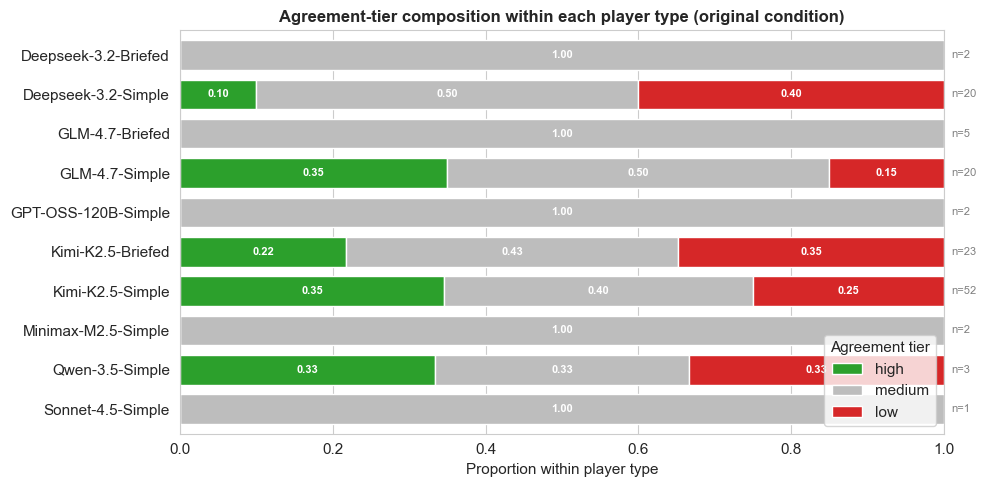

In [ ]:
def characterize_agreement_tiers(ea_data, condition):
    """Compare high- vs low-agreement episodes for a given condition.

    Recomputes tier boundaries from this condition's own `use_nuke_std`
    quartiles (so high/low groups are balanced within-condition), runs
    Mann-Whitney U tests on episode features, and plots the tier
    composition per player type.
    """
    ea_cond = ea_data[ea_data['condition'] == condition].copy()
    q25, q75 = ea_cond['use_nuke_std'].quantile([0.25, 0.75])
    ea_cond['agreement_tier'] = pd.cut(
        ea_cond['use_nuke_std'],
        bins=[-np.inf, q25, q75, np.inf],
        labels=['high', 'medium', 'low'],
    )

    high = ea_cond[ea_cond['agreement_tier'] == 'high']
    low = ea_cond[ea_cond['agreement_tier'] == 'low']

    compare_cols = ['prev_use_nuke', 'prev_nuke', 'after_use_nuke', 'after_nuke',
                    'original_use_nuke_delta', 'original_nuke_delta', 'turn',
                    'use_nuke_mean', 'nuke_mean']

    rows = []
    for col in compare_cols:
        h_vals = high[col].dropna()
        l_vals = low[col].dropna()
        if len(h_vals) > 0 and len(l_vals) > 0:
            _, p = mannwhitneyu(h_vals, l_vals, alternative='two-sided')
        else:
            p = np.nan
        rows.append({
            'feature': col,
            f'high (n={len(h_vals)})': f'{h_vals.mean():.2f} +/- {h_vals.std():.2f}',
            f'low (n={len(l_vals)})':  f'{l_vals.mean():.2f} +/- {l_vals.std():.2f}',
            'p_value': p,
            'sig': pvalue_to_stars(p),
        })

    comparison = pd.DataFrame(rows).sort_values('p_value').reset_index(drop=True)
    display(Markdown(f'### High vs Low Agreement: Episode Features ({condition} condition)'))
    display(Markdown(f'Tier thresholds (within-condition quartiles on `use_nuke_std`): '
                     f'Q25={q25:.3f}, Q75={q75:.3f}'))
    display(comparison.round(3))

    # Tier composition per player type
    dist = (ea_cond
            .groupby(['player_type', 'agreement_tier'], observed=True)
            .size().unstack(fill_value=0))
    dist = dist.reindex(columns=['high', 'medium', 'low'], fill_value=0)
    dist_pct = dist.div(dist.sum(axis=1), axis=0)
    dist_pct = dist_pct.loc[sort_player_types(dist_pct.index)]
    n_per_type = dist.sum(axis=1).loc[dist_pct.index]

    fig, ax = plt.subplots(figsize=(10, 5))
    dist_pct[['high', 'medium', 'low']].plot(
        kind='barh', stacked=True,
        color=['#2ca02c', '#bdbdbd', '#d62728'],
        ax=ax, width=0.75,
    )
    ax.set_xlabel('Proportion within player type')
    ax.set_ylabel('')
    ax.set_title(f'Agreement-tier composition within each player type ({condition} condition)',
                 fontsize=12, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.legend(title='Agreement tier', loc='lower right')
    ax.invert_yaxis()
    for c in ax.containers:
        labels = [f'{v:.2f}' if v > 0.05 else '' for v in c.datavalues]
        ax.bar_label(c, labels=labels, label_type='center',
                     fontsize=8, color='white', fontweight='bold')
    for i, n in enumerate(n_per_type):
        ax.text(1.01, i, f'n={int(n)}', va='center', fontsize=8, color='gray')
    plt.tight_layout()
    plt.show()

    return comparison


_ = characterize_agreement_tiers(ea_multi, 'original')

### High vs Low Agreement: Episode Features (high-stakes-no-rationale-ethical condition)

Tier thresholds (within-condition quartiles on `use_nuke_std`): Q25=19.163, Q75=30.488

,feature,high (n=33),low (n=33),p_value,sig
0,original_use_nuke_delta,56.21 +/- 34.03,7.42 +/- 4.98,0.000,***
1,prev_use_nuke,40.76 +/- 32.65,91.15 +/- 5.51,0.000,***
2,use_nuke_mean,31.61 +/- 25.69,58.24 +/- 8.30,0.000,***
3,original_nuke_delta,21.97 +/- 27.58,2.12 +/- 4.34,0.000,***
4,prev_nuke,73.48 +/- 30.48,96.97 +/- 4.83,0.000,***
5,nuke_mean,59.67 +/- 23.11,68.69 +/- 7.82,0.147,
6,turn,407.39 +/- 42.59,416.30 +/- 43.31,0.612,
7,after_nuke,95.45 +/- 17.74,99.09 +/- 2.64,0.636,
8,after_use_nuke,96.97 +/- 6.37,98.58 +/- 3.12,0.903,


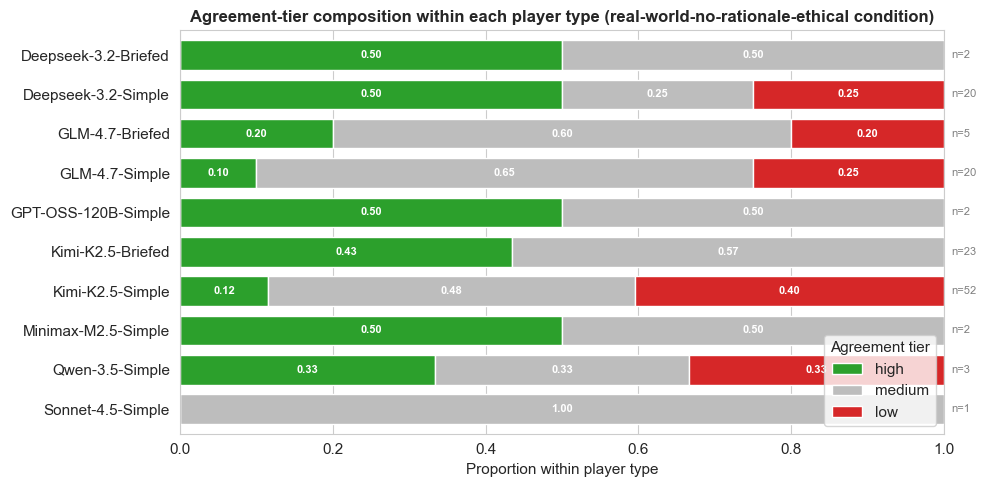

In [ ]:
_ = characterize_agreement_tiers(ea_multi, 'high-stakes-no-rationale-ethical')

## 8. Leave-One-Out Model Contribution

For each condition and model, compute the change in cross-model standard deviation when that model is removed from the available-model set.

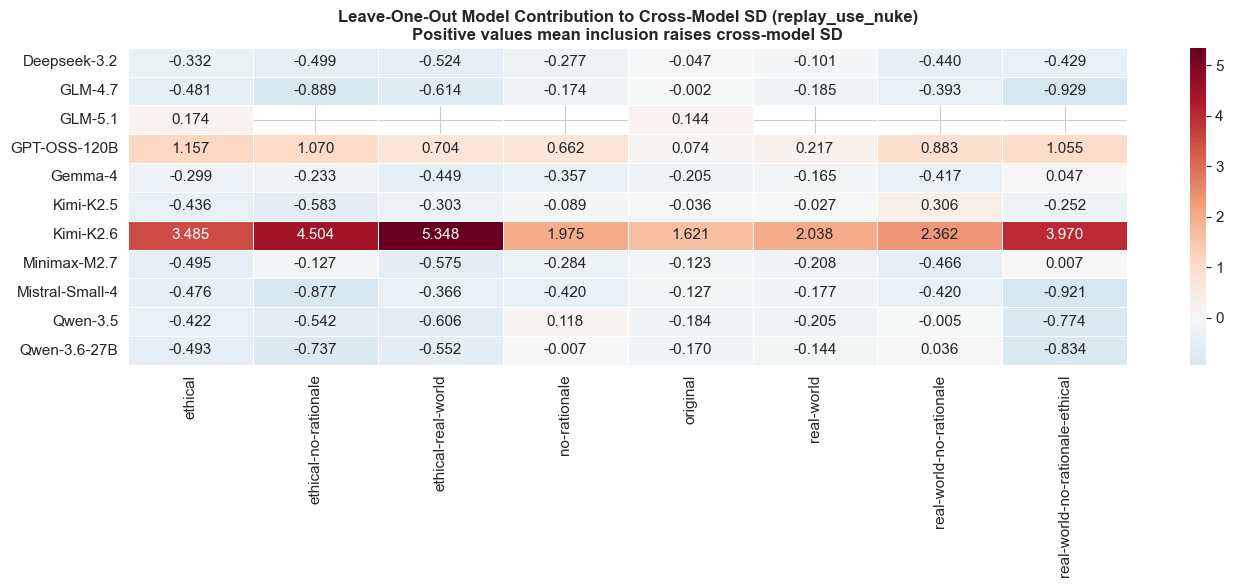

In [ ]:
# Leave-one-out model contribution to cross-model SD
loo_results = []
for cond in MULTI_MODEL_CONDITIONS:
    cond_data = model_means[model_means['condition'] == cond]
    available_models = sorted(cond_data['replay_model_canonical'].unique())

    if len(available_models) < 3:
        continue

    # Full-set std per episode
    full_std = (
        cond_data.groupby(EPISODE_COLS, observed=True)['replay_use_nuke']
        .std().rename('full_std')
    )

    for model in available_models:
        # Std without this model
        others = cond_data[cond_data['replay_model_canonical'] != model]
        loo_std = (
            others.groupby(EPISODE_COLS, observed=True)['replay_use_nuke']
            .std().rename('loo_std')
        )
        merged = pd.concat([full_std, loo_std], axis=1).dropna()
        delta = (merged['full_std'] - merged['loo_std']).mean()
        loo_results.append({
            'condition': cond,
            'model': model,
            'mean_delta_std': delta,  # positive = inclusion raises cross-model SD
        })

loo_df = pd.DataFrame(loo_results)
loo_pivot = loo_df.pivot_table(index='model', columns='condition', values='mean_delta_std')

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    loo_pivot, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
    linewidths=0.5, ax=ax,
)
ax.set_title('Leave-One-Out Model Contribution to Cross-Model SD (replay_use_nuke)\n'
             'Positive values mean inclusion raises cross-model SD',
             fontsize=12, fontweight='bold')
ax.set_ylabel('')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

## 9. Cross-Condition Agreement Stability

Compute Spearman correlations between condition pairs using per-episode `use_nuke_std` values.

C:\Users\John Chen\AppData\Local\Temp\ipykernel_249100\2228675443.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_std = ea_multi.pivot_table(


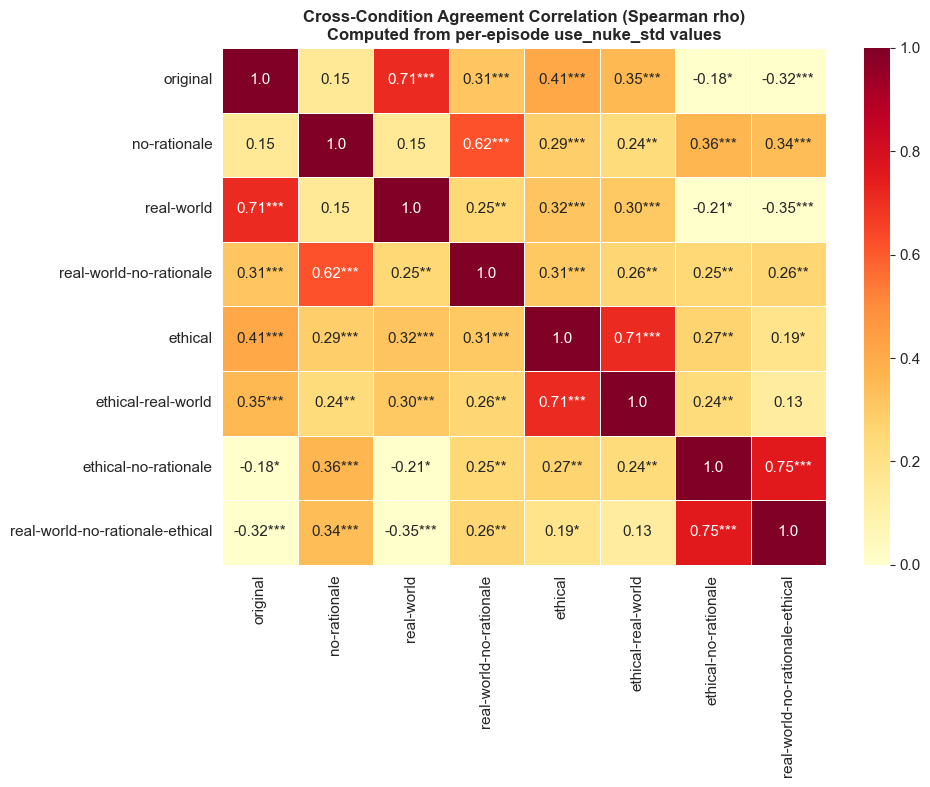

In [ ]:
# Cross-condition correlation of per-episode agreement
pivot_std = ea_multi.pivot_table(
    index=EPISODE_COLS, columns='condition', values='use_nuke_std'
)

# Spearman correlation matrix
conds = [c for c in pivot_std.columns if c in MULTI_MODEL_CONDITIONS]
n_conds = len(conds)
corr_vals = np.ones((n_conds, n_conds))
pval_vals = np.zeros((n_conds, n_conds))

for i, c1 in enumerate(conds):
    for j, c2 in enumerate(conds):
        if i >= j:
            continue
        valid = pivot_std[[c1, c2]].dropna()
        if len(valid) > 2:
            rho, p = spearmanr(valid[c1], valid[c2])
        else:
            rho, p = np.nan, np.nan
        corr_vals[i, j] = corr_vals[j, i] = rho
        pval_vals[i, j] = pval_vals[j, i] = p

corr_matrix = pd.DataFrame(corr_vals, index=conds, columns=conds)
# Annotate with stars
annot = corr_matrix.round(2).astype(str)
for i, c1 in enumerate(conds):
    for j, c2 in enumerate(conds):
        if i >= j:
            continue
        p = pval_vals[i, j]
        stars = pvalue_to_stars(p) if not np.isnan(p) else ''
        label = f'{corr_vals[i, j]:.2f}{stars}'
        annot.iloc[i, j] = label
        annot.iloc[j, i] = label

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix, annot=annot, fmt='',
    cmap='YlOrRd', vmin=0, vmax=1, linewidths=0.5, ax=ax,
)
ax.set_title('Cross-Condition Agreement Correlation (Spearman rho)\n'
             'Computed from per-episode use_nuke_std values',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Exemplar Episode Tables

List episodes with the lowest and highest mean cross-model standard deviation across conditions.

In [ ]:
# Grand highest-/lowest-agreement episodes: rank by mean cross-model SD across all conditions
episode_grand = (
    ea_multi.groupby(EPISODE_COLS, observed=True)
    .agg(
        mean_direction_agree=('use_nuke_direction_agree', 'mean'),
        mean_use_nuke=('use_nuke_mean', 'mean'),
        mean_use_nuke_std=('use_nuke_std', 'mean'),
        n_conditions=('condition', 'nunique'),
    )
    .reset_index()
)
# Attach per-episode state (constant across conditions)
episode_grand = episode_grand.merge(
    episode_state[[*EPISODE_COLS, 'player_type', 'prev_use_nuke', 'after_use_nuke',
                   'original_use_nuke_delta']],
    on=EPISODE_COLS, how='left',
)

show_cols = [*EPISODE_COLS, 'player_type',
             'mean_use_nuke', 'mean_use_nuke_std',
             'prev_use_nuke', 'after_use_nuke', 'original_use_nuke_delta']

display(Markdown('### Lowest Cross-Model SD Episodes'))
top_agree = episode_grand.nsmallest(20, 'mean_use_nuke_std')[show_cols]
display(top_agree.reset_index(drop=True))

display(Markdown('### Highest Cross-Model SD Episodes'))
top_disagree = episode_grand.nlargest(20, 'mean_use_nuke_std')[show_cols]
display(top_disagree.reset_index(drop=True))

### Lowest Cross-Model SD Episodes

,game_id,player_id,turn,player_type,mean_use_nuke,mean_use_nuke_std,prev_use_nuke,after_use_nuke,original_use_nuke_delta
0,798b96e3-886a-45ea-9bab-9cabcb1f2549,3,324,Kimi-K2.5-Briefed,0.000000,0.000000,0.0,100.0,100.0
1,f58d4ebd-1a92-494e-8b61-cdf51d4e4128,4,399,GLM-4.7-Simple,0.683712,1.619271,0.0,80.0,80.0
2,dac3ed8c-f746-4d4b-a059-afd967efb51a,3,450,Kimi-K2.5-Briefed,1.647727,3.399949,0.0,100.0,100.0
3,519e09dd-d268-4364-a113-4ffde99d7742,3,436,Kimi-K2.5-Briefed,1.939394,5.388537,0.0,100.0,100.0
4,87da240a-4d1f-49d4-a01a-ad8be42c564c,3,335,Kimi-K2.5-Briefed,25.589015,6.548787,30.0,100.0,70.0
5,52dcb454-ba1c-4fca-884e-96ab1d4ff6f9,3,396,Kimi-K2.5-Briefed,62.003788,7.291729,65.0,80.0,15.0
6,085cfce3-75ee-4459-b7b0-c49c9a27f651,4,408,GLM-4.7-Simple,79.041667,8.084387,80.0,100.0,20.0
7,a0105385-3117-4b7b-894a-2050d16e1785,2,421,Kimi-K2.5-Simple,84.780303,8.442224,85.0,100.0,15.0
8,c12ee2e2-205b-4c98-8649-ceedb2e11ed7,3,391,Kimi-K2.5-Briefed,79.589015,9.002645,85.0,100.0,15.0
9,32c8959d-e839-425e-80c0-8ab65d8cc9e4,2,413,Kimi-K2.5-Simple,4.691288,9.020278,0.0,100.0,100.0


### Highest Cross-Model SD Episodes

,game_id,player_id,turn,player_type,mean_use_nuke,mean_use_nuke_std,prev_use_nuke,after_use_nuke,original_use_nuke_delta
0,a64825f5-bb4a-4bd6-aadb-8a5077421ff4,2,482,Kimi-K2.5-Simple,70.295455,30.134355,90.0,95.0,5.0
1,7f219acb-6c23-49dc-bde1-fa1602646bf5,3,489,Kimi-K2.5-Briefed,50.933712,29.304957,0.0,100.0,100.0
2,9e832844-b9a2-479a-836c-d862a2ff0c76,3,354,Kimi-K2.5-Briefed,31.604167,25.574441,0.0,100.0,100.0
3,67e5a867-cf05-4f7f-b55e-ff54940ad8ac,2,408,Kimi-K2.5-Simple,60.770833,25.377083,80.0,95.0,15.0
4,f49a31d9-6a4f-4409-9eb5-2018e204a760,4,431,GLM-4.7-Simple,55.136364,24.919568,75.0,80.0,5.0
5,9a957ab0-0db2-4971-8c3b-320736031605,2,484,Qwen-3.5-Simple,78.445076,24.488020,95.0,100.0,5.0
6,8dc97838-d90f-4231-9827-b57c00c4e6e6,2,403,Kimi-K2.5-Simple,76.668939,24.274645,95.0,100.0,5.0
7,8144e384-227c-4376-a48b-8675c9caab80,6,433,Deepseek-3.2-Simple,27.632576,24.220349,0.0,100.0,100.0
8,5a738af7-8523-492e-b0b1-da3aeb0af7f1,2,417,Kimi-K2.5-Simple,73.920455,24.162828,90.0,100.0,10.0
9,c3fab47e-b30a-4fab-9cea-f4e8c677c4d6,2,439,Kimi-K2.5-Simple,75.475379,23.118391,95.0,100.0,5.0


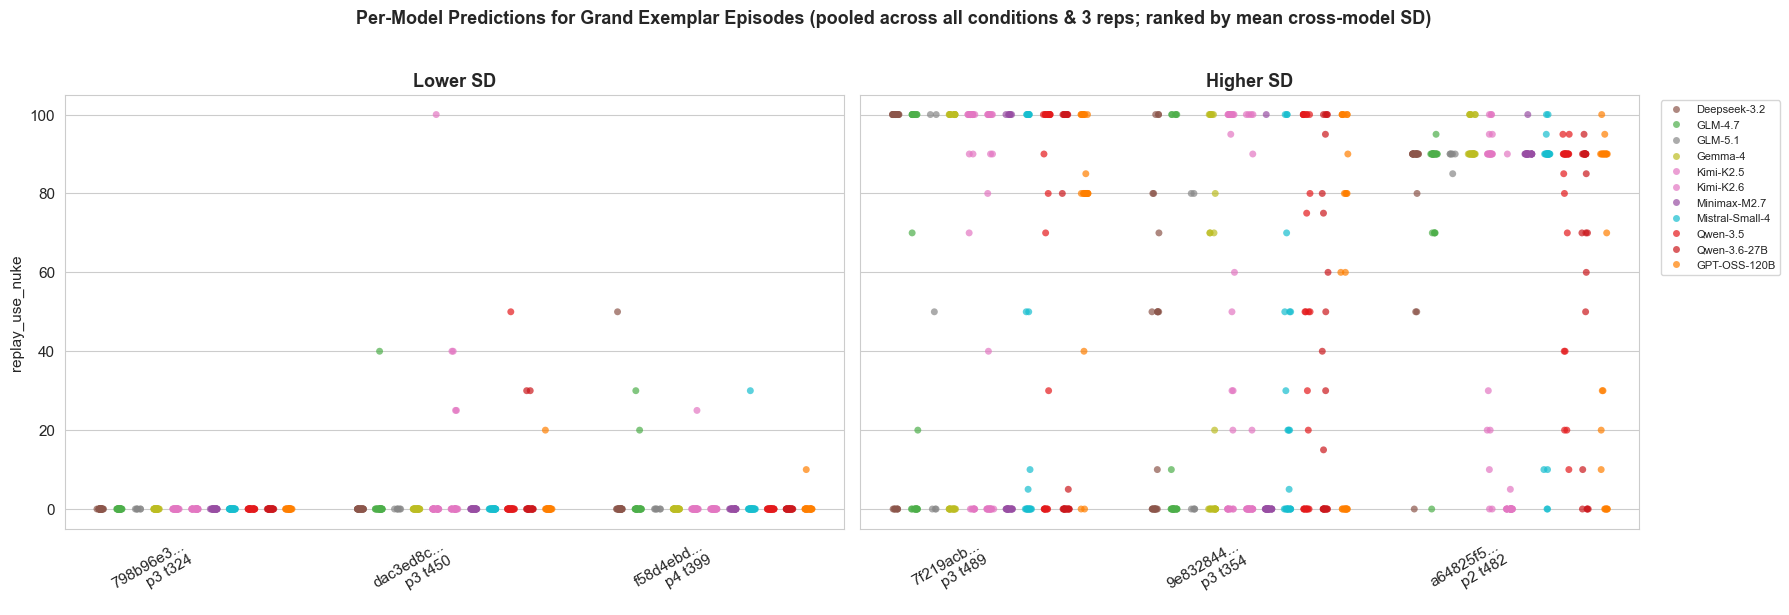

In [ ]:
# Strip plot: per-model predictions for selected low/high cross-model-SD episodes (all conditions shown side by side)
exemplar_high_ids = episode_grand.nsmallest(3, 'mean_use_nuke_std')[EPISODE_COLS].assign(
    exemplar_type='Lower SD')
exemplar_low_ids = episode_grand.nlargest(3, 'mean_use_nuke_std')[EPISODE_COLS].assign(
    exemplar_type='Higher SD')
exemplar_ids = pd.concat([exemplar_high_ids, exemplar_low_ids])

# Merge back to raw data (all 3 reps per model, every condition the episode appears in)
exemplar_data = df.merge(exemplar_ids, on=EPISODE_COLS)
exemplar_data['episode_label'] = (
    exemplar_data['game_id'].str[:8] + '...\n'
    + 'p' + exemplar_data['player_id'].astype(str)
    + ' t' + exemplar_data['turn'].astype(str)
)

palette = get_model_palette(sorted(exemplar_data['replay_model_canonical'].unique()))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for idx, (etype, ax) in enumerate(zip(['Lower SD', 'Higher SD'], axes)):
    subset = exemplar_data[exemplar_data['exemplar_type'] == etype]
    sns.stripplot(
        data=subset, x='episode_label', y='replay_use_nuke',
        hue='replay_model_canonical', palette=palette,
        dodge=True, jitter=0.15, alpha=0.7, size=5, ax=ax,
    )
    ax.set_title(etype, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('replay_use_nuke' if idx == 0 else '')
    ax.tick_params(axis='x', rotation=30)
    for label in ax.get_xticklabels():
        label.set_ha('right')
    if idx == 0:
        ax.get_legend().remove()
    else:
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

fig.suptitle('Per-Model Predictions for Grand Exemplar Episodes '
             '(pooled across all conditions & 3 reps; ranked by mean cross-model SD)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()